In [1]:
%load_ext autoreload

In [2]:
%autoreload 2

# Importación de Funciones y dependencias

In [3]:
# Algoritmo genetico
from pymoo.algorithms.soo.nonconvex.ga import GA
from pymoo.optimize import minimize

# Funciones de pruebas
from pymoo_custom_test_problems.rastrigin import RastriginFunction
from pymoo_custom_test_problems.branin import Branin
from pymoo_custom_test_problems.discontinuousIntegrand import DiscontinuousIntegrand
from pymoo_custom_test_problems.environmentalModel import EnvironmentalModel
from pymoo_custom_test_problems.ishigami import Ishigami
from pymoo_custom_test_problems.park91a import Park91a
from pymoo_custom_test_problems.park91b import Park91b
from pymoo_custom_test_problems.roos_arnold63 import RoosArnold63

# Solver tradicional
from scipy.optimize import minimize as scipy_minimize

# Utilidades y funciones auxiliares para graficación
import numpy as np
import matplotlib.pyplot as plt
from pymoo.visualization.fitness_landscape import FitnessLandscape
from utils.utils import to_scipy
from utils.graphs import ScipyRecorder, pymoo_path, plot_steps
import time
import json


RESULSTS = {}
RESULSTS_mean = {}

# Función Rastringin

[GA] Tiempo promedio 0.40633901755015056
[GA] No. Invocaciones promedio 20000.0
[L-BFGS-B] Tiempo promedio 0.0008078069639547418
[L-BFGS-B] No. Invocaciones promedio 38.0
{
    "Rastrigin": {
        "GA": {
            "Time": 0.40633901755015056,
            "No_Invok": 20000.0,
            "fx_mean": 4.364392233687416e-06,
            "fx_std": 8.78557471960017e-06,
            "fx_best": 8.400036222155904e-11,
            "success_rate": 1.0
        },
        "L-BFGS-B": {
            "Time": 0.0008078069639547418,
            "No_Invok": 38.0,
            "fx_mean": 12.901221280309434,
            "fx_std": 10.158250077530292,
            "fx_best": 0.9949590570933005,
            "success_rate": 0.0
        }
    },
    "Branin": {
        "GA": {
            "Time": 0.4030147155125936,
            "No_Invok": 20000.0,
            "fx_mean": 0.3978877730653415,
            "fx_std": 1.1637895602594163e-06,
            "fx_best": 0.39788735797025865,
            "success_rate": 1

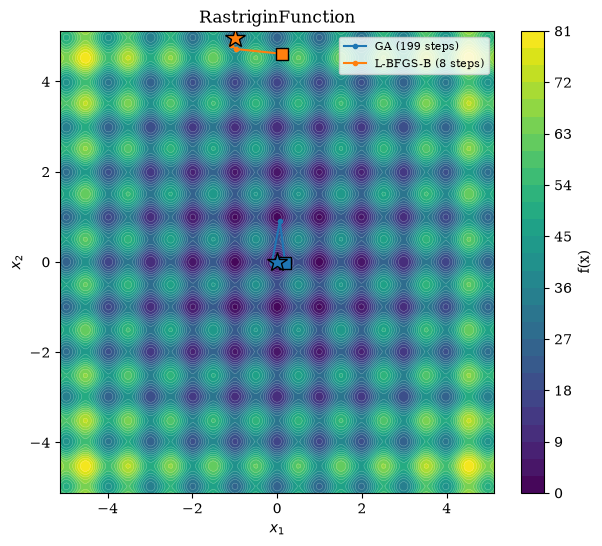

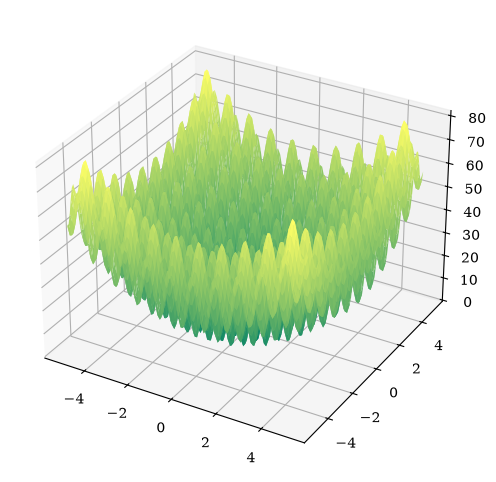

In [13]:
# Pymoo
problem = RastriginFunction(n_var=2)

# Scipy
f, bounds = to_scipy(problem=problem)
method = "L-BFGS-B"


# Corremos 30 veces cada algoritmo y obtenemos un promedio
GA_mean_time = 0
GA_mean_invok = 0
GA_fx = []
# ==================== MEAN ====================
for i in range(1,31):
    # Algoritmo Genetico
    algorithm = GA(pop_size=100)
    res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=i)

    GA_mean_time += res_pymoo.exec_time
    GA_mean_invok += res_pymoo.algorithm.evaluator.n_eval
    GA_fx.append(float(res_pymoo.F[0]))

GA_mean_time = GA_mean_time / 30
GA_mean_invok = GA_mean_invok / 30

print("[GA] Tiempo promedio", GA_mean_time)
print("[GA] No. Invocaciones promedio", GA_mean_invok)


Scipy_mean_time = 0
Scipy_mean_invok = 0
Scipy_fx = []
for i in range(1, 31):
    # Scipy
    rng = np.random.default_rng(i)
    x0 = rng.uniform(problem.xl, problem.xu)

    inicio = time.perf_counter()
    res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds)  # traditional
    fin = time.perf_counter()

    Scipy_mean_time += (fin - inicio)
    Scipy_mean_invok += res_scipy.nfev
    Scipy_fx.append(float(res_scipy.fun))

Scipy_mean_invok = Scipy_mean_invok / 30
Scipy_mean_time =  Scipy_mean_time / 30

print(f"[{method}] Tiempo promedio", Scipy_mean_time)
print(f"[{method}] No. Invocaciones promedio", Scipy_mean_invok)

RESULSTS_mean[problem.foo_name] = {
    "GA": {
        "Time": GA_mean_time,
        "No_Invok": GA_mean_invok,
        "fx_mean": float(np.mean(GA_fx)),
        "fx_std":  float(np.std(GA_fx, ddof=1)),
        "fx_best": float(np.min(GA_fx)),
        "success_rate": float(np.mean(np.abs(np.array(GA_fx) - problem.f_opt) <= 1e-4)),

    },
    f"{method}": {
        "Time": Scipy_mean_time,
        "No_Invok": Scipy_mean_invok,
        "fx_mean": float(np.mean(Scipy_fx)),
        "fx_std":  float(np.std(Scipy_fx, ddof=1)),
        "fx_best": float(np.min(Scipy_fx)),
        "success_rate": float(np.mean(np.abs(np.array(Scipy_fx) - problem.f_opt) <= 1e-4)),
    }
}


# ==================== GRAPHS ====================
# Algoritmo Genetico
algorithm = GA(pop_size=100)
res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=15, save_history=True)

# Guardamos el historial de los pasos por epoca
path_pymoo_ga = pymoo_path(res_pymoo)

# Scipy
rng = np.random.default_rng(1)
x0 = rng.uniform(problem.xl, problem.xu)

# Guardamos el historial de los pasos por iteración
rec = ScipyRecorder(x0)    
inicio = time.perf_counter()
res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds, callback=rec)  # traditional
fin = time.perf_counter()
path_steps_scipy = rec.path


plot_steps(problem, {"GA": path_pymoo_ga, method : path_steps_scipy})
surface = FitnessLandscape(problem, angle=(45, 45), _type="surface").show()          # 3-D surface




# ==================== RESULTS ====================
GA_result = {
    "Best_x": res_pymoo.X.tolist(), 
    "fx": res_pymoo.F[0], 
    "No_invok": res_pymoo.algorithm.evaluator.n_eval,
    "Time": res_pymoo.exec_time
}

Scipy_method = {
    "Best_x": res_scipy.x.tolist(), 
    "fx": res_scipy.fun, 
    "No_invok": res_scipy.nfev,
    "Time": fin - inicio
}

RESULSTS[problem.foo_name] = {
    "GA": GA_result,
    method: Scipy_method
}

print(json.dumps(RESULSTS_mean, indent=4))
print(json.dumps(RESULSTS, indent=4))



# Función Branin

[GA] Tiempo promedio 0.4030147155125936
[GA] No. Invocaciones promedio 20000.0
[L-BFGS-B] Tiempo promedio 0.0006984250290164103
[L-BFGS-B] No. Invocaciones promedio 31.9
{
    "Rastrigin": {
        "GA": {
            "Time": 0.41114555994669594,
            "No_Invok": 20000.0,
            "fx_mean": 4.364392233687416e-06,
            "fx_std": 8.78557471960017e-06,
            "fx_best": 8.400036222155904e-11,
            "success_rate": 1.0
        },
        "L-BFGS-B": {
            "Time": 0.0008864083346755554,
            "No_Invok": 38.0,
            "fx_mean": 12.901221280309434,
            "fx_std": 10.158250077530292,
            "fx_best": 0.9949590570933005,
            "success_rate": 0.0
        }
    },
    "Branin": {
        "GA": {
            "Time": 0.4030147155125936,
            "No_Invok": 20000.0,
            "fx_mean": 0.3978877730653415,
            "fx_std": 1.1637895602594163e-06,
            "fx_best": 0.39788735797025865,
            "success_rate": 1.

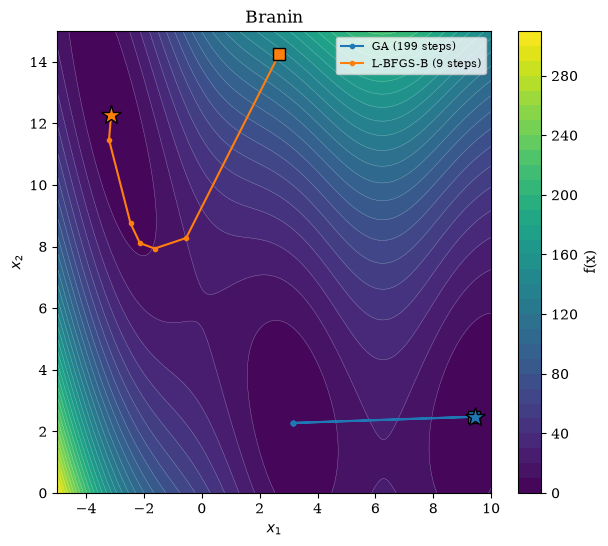

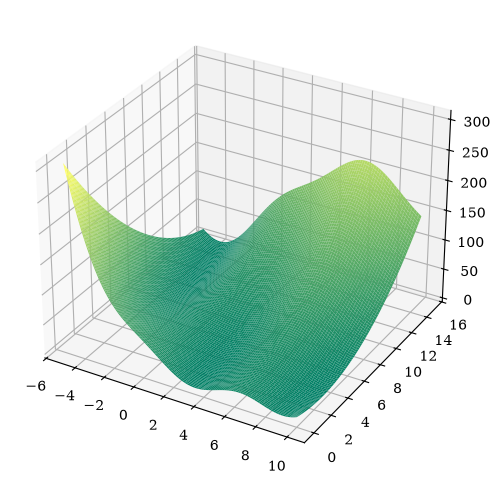

In [5]:
# Pymoo
problem = Branin()

# Scipy
f, bounds = to_scipy(problem=problem)
method = "L-BFGS-B"


# Corremos 30 veces cada algoritmo y obtenemos un promedio
GA_mean_time = 0
GA_mean_invok = 0
GA_fx = []
# ==================== MEAN ====================
for i in range(1,31):
    # Algoritmo Genetico
    algorithm = GA(pop_size=100)
    res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=i)

    GA_mean_time += res_pymoo.exec_time
    GA_mean_invok += res_pymoo.algorithm.evaluator.n_eval
    GA_fx.append(float(res_pymoo.F[0]))

GA_mean_time = GA_mean_time / 30
GA_mean_invok = GA_mean_invok / 30

print("[GA] Tiempo promedio", GA_mean_time)
print("[GA] No. Invocaciones promedio", GA_mean_invok)


Scipy_mean_time = 0
Scipy_mean_invok = 0
Scipy_fx = []
for i in range(1, 31):
    # Scipy
    rng = np.random.default_rng(i)
    x0 = rng.uniform(problem.xl, problem.xu)

    inicio = time.perf_counter()
    res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds)  # traditional
    fin = time.perf_counter()

    Scipy_mean_time += (fin - inicio)
    Scipy_mean_invok += res_scipy.nfev
    Scipy_fx.append(float(res_scipy.fun))

Scipy_mean_invok = Scipy_mean_invok / 30
Scipy_mean_time =  Scipy_mean_time / 30

print(f"[{method}] Tiempo promedio", Scipy_mean_time)
print(f"[{method}] No. Invocaciones promedio", Scipy_mean_invok)

RESULSTS_mean[problem.foo_name] = {
    "GA": {
        "Time": GA_mean_time,
        "No_Invok": GA_mean_invok,
        "fx_mean": float(np.mean(GA_fx)),
        "fx_std":  float(np.std(GA_fx, ddof=1)),
        "fx_best": float(np.min(GA_fx)),
        "success_rate": float(np.mean(np.abs(np.array(GA_fx) - problem.f_opt) <= 1e-4)),

    },
    f"{method}": {
        "Time": Scipy_mean_time,
        "No_Invok": Scipy_mean_invok,
        "fx_mean": float(np.mean(Scipy_fx)),
        "fx_std":  float(np.std(Scipy_fx, ddof=1)),
        "fx_best": float(np.min(Scipy_fx)),
        "success_rate": float(np.mean(np.abs(np.array(Scipy_fx) - problem.f_opt) <= 1e-4)),
    }
}


# ==================== GRAPHS ====================
# Algoritmo Genetico
algorithm = GA(pop_size=100)
res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=15, save_history=True)

# Guardamos el historial de los pasos por epoca
path_pymoo_ga = pymoo_path(res_pymoo)

# Scipy
rng = np.random.default_rng(1)
x0 = rng.uniform(problem.xl, problem.xu)

# Guardamos el historial de los pasos por iteración
rec = ScipyRecorder(x0)    
inicio = time.perf_counter()
res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds, callback=rec)  # traditional
fin = time.perf_counter()
path_steps_scipy = rec.path


plot_steps(problem, {"GA": path_pymoo_ga, method : path_steps_scipy})
surface = FitnessLandscape(problem, angle=(45, 45), _type="surface").show()          # 3-D surface




# ==================== RESULTS ====================
GA_result = {
    "Best_x": res_pymoo.X.tolist(), 
    "fx": res_pymoo.F[0], 
    "No_invok": res_pymoo.algorithm.evaluator.n_eval,
    "Time": res_pymoo.exec_time
}

Scipy_method = {
    "Best_x": res_scipy.x.tolist(), 
    "fx": res_scipy.fun, 
    "No_invok": res_scipy.nfev,
    "Time": fin - inicio
}

RESULSTS[problem.foo_name] = {
    "GA": GA_result,
    method: Scipy_method
}

print(json.dumps(RESULSTS_mean, indent=4))
print(json.dumps(RESULSTS, indent=4))



# Función Ishigami

[GA] Tiempo promedio 0.4408850193023682
[GA] No. Invocaciones promedio 20000.0
[L-BFGS-B] Tiempo promedio 0.0006483361008577049
[L-BFGS-B] No. Invocaciones promedio 33.46666666666667
{
    "Rastrigin": {
        "GA": {
            "Time": 0.41114555994669594,
            "No_Invok": 20000.0,
            "fx_mean": 4.364392233687416e-06,
            "fx_std": 8.78557471960017e-06,
            "fx_best": 8.400036222155904e-11,
            "success_rate": 1.0
        },
        "L-BFGS-B": {
            "Time": 0.0008864083346755554,
            "No_Invok": 38.0,
            "fx_mean": 12.901221280309434,
            "fx_std": 10.158250077530292,
            "fx_best": 0.9949590570933005,
            "success_rate": 0.0
        }
    },
    "Branin": {
        "GA": {
            "Time": 0.4030147155125936,
            "No_Invok": 20000.0,
            "fx_mean": 0.3978877730653415,
            "fx_std": 1.1637895602594163e-06,
            "fx_best": 0.39788735797025865,
            "succ

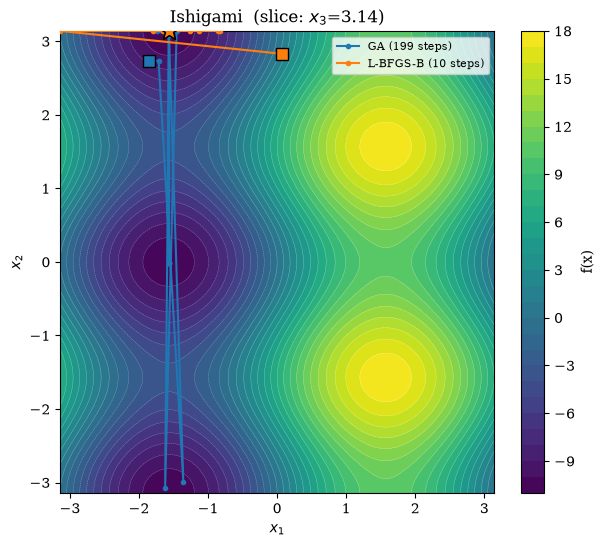

In [6]:
# Pymoo
problem = Ishigami()

# Scipy
f, bounds = to_scipy(problem=problem)
method = "L-BFGS-B"


# Corremos 30 veces cada algoritmo y obtenemos un promedio
GA_mean_time = 0
GA_mean_invok = 0
GA_fx = []
# ==================== MEAN ====================
for i in range(1,31):
    # Algoritmo Genetico
    algorithm = GA(pop_size=100)
    res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=i)

    GA_mean_time += res_pymoo.exec_time
    GA_mean_invok += res_pymoo.algorithm.evaluator.n_eval
    GA_fx.append(float(res_pymoo.F[0]))

GA_mean_time = GA_mean_time / 30
GA_mean_invok = GA_mean_invok / 30

print("[GA] Tiempo promedio", GA_mean_time)
print("[GA] No. Invocaciones promedio", GA_mean_invok)


Scipy_mean_time = 0
Scipy_mean_invok = 0
Scipy_fx = []
for i in range(1, 31):
    # Scipy
    rng = np.random.default_rng(i)
    x0 = rng.uniform(problem.xl, problem.xu)

    inicio = time.perf_counter()
    res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds)  # traditional
    fin = time.perf_counter()

    Scipy_mean_time += (fin - inicio)
    Scipy_mean_invok += res_scipy.nfev
    Scipy_fx.append(float(res_scipy.fun))

Scipy_mean_invok = Scipy_mean_invok / 30
Scipy_mean_time =  Scipy_mean_time / 30

print(f"[{method}] Tiempo promedio", Scipy_mean_time)
print(f"[{method}] No. Invocaciones promedio", Scipy_mean_invok)

RESULSTS_mean[problem.foo_name] = {
    "GA": {
        "Time": GA_mean_time,
        "No_Invok": GA_mean_invok,
        "fx_mean": float(np.mean(GA_fx)),
        "fx_std":  float(np.std(GA_fx, ddof=1)),
        "fx_best": float(np.min(GA_fx)),
        "success_rate": float(np.mean(np.abs(np.array(GA_fx) - problem.f_opt) <= 1e-4)),

    },
    f"{method}": {
        "Time": Scipy_mean_time,
        "No_Invok": Scipy_mean_invok,
        "fx_mean": float(np.mean(Scipy_fx)),
        "fx_std":  float(np.std(Scipy_fx, ddof=1)),
        "fx_best": float(np.min(Scipy_fx)),
        "success_rate": float(np.mean(np.abs(np.array(Scipy_fx) - problem.f_opt) <= 1e-4)),
    }
}


# ==================== GRAPHS ====================
# Algoritmo Genetico
algorithm = GA(pop_size=100)
res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=15, save_history=True)

# Guardamos el historial de los pasos por epoca
path_pymoo_ga = pymoo_path(res_pymoo)

# Scipy
rng = np.random.default_rng(1)
x0 = rng.uniform(problem.xl, problem.xu)

# Guardamos el historial de los pasos por iteración
rec = ScipyRecorder(x0)    
inicio = time.perf_counter()
res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds, callback=rec)  # traditional
fin = time.perf_counter()
path_steps_scipy = rec.path


plot_steps(problem, {"GA": path_pymoo_ga, method : path_steps_scipy})
# surface = FitnessLandscape(problem, angle=(45, 45), _type="surface").show()          # 3-D surface




# ==================== RESULTS ====================
GA_result = {
    "Best_x": res_pymoo.X.tolist(), 
    "fx": res_pymoo.F[0], 
    "No_invok": res_pymoo.algorithm.evaluator.n_eval,
    "Time": res_pymoo.exec_time
}

Scipy_method = {
    "Best_x": res_scipy.x.tolist(), 
    "fx": res_scipy.fun, 
    "No_invok": res_scipy.nfev,
    "Time": fin - inicio
}

RESULSTS[problem.foo_name] = {
    "GA": GA_result,
    method: Scipy_method
}

print(json.dumps(RESULSTS_mean, indent=4))
print(json.dumps(RESULSTS, indent=4))



# Park (1991) Function 2

[GA] Tiempo promedio 0.45570082664489747
[GA] No. Invocaciones promedio 20000.0
[L-BFGS-B] Tiempo promedio 0.0003255251368197302
[L-BFGS-B] No. Invocaciones promedio 17.5
{
    "Rastrigin": {
        "GA": {
            "Time": 0.41114555994669594,
            "No_Invok": 20000.0,
            "fx_mean": 4.364392233687416e-06,
            "fx_std": 8.78557471960017e-06,
            "fx_best": 8.400036222155904e-11,
            "success_rate": 1.0
        },
        "L-BFGS-B": {
            "Time": 0.0008864083346755554,
            "No_Invok": 38.0,
            "fx_mean": 12.901221280309434,
            "fx_std": 10.158250077530292,
            "fx_best": 0.9949590570933005,
            "success_rate": 0.0
        }
    },
    "Branin": {
        "GA": {
            "Time": 0.4030147155125936,
            "No_Invok": 20000.0,
            "fx_mean": 0.3978877730653415,
            "fx_std": 1.1637895602594163e-06,
            "fx_best": 0.39788735797025865,
            "success_rate": 1

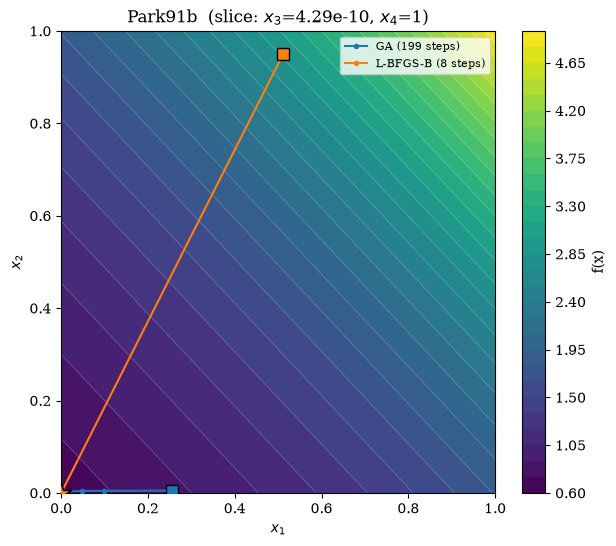

In [7]:
# Pymoo
problem = Park91b()

# Scipy
f, bounds = to_scipy(problem=problem)
method = "L-BFGS-B"


# Corremos 30 veces cada algoritmo y obtenemos un promedio
GA_mean_time = 0
GA_mean_invok = 0
GA_fx = []
# ==================== MEAN ====================
for i in range(1,31):
    # Algoritmo Genetico
    algorithm = GA(pop_size=100)
    res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=i)

    GA_mean_time += res_pymoo.exec_time
    GA_mean_invok += res_pymoo.algorithm.evaluator.n_eval
    GA_fx.append(float(res_pymoo.F[0]))

GA_mean_time = GA_mean_time / 30
GA_mean_invok = GA_mean_invok / 30

print("[GA] Tiempo promedio", GA_mean_time)
print("[GA] No. Invocaciones promedio", GA_mean_invok)


Scipy_mean_time = 0
Scipy_mean_invok = 0
Scipy_fx = []
for i in range(1, 31):
    # Scipy
    rng = np.random.default_rng(i)
    x0 = rng.uniform(problem.xl, problem.xu)

    inicio = time.perf_counter()
    res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds)  # traditional
    fin = time.perf_counter()

    Scipy_mean_time += (fin - inicio)
    Scipy_mean_invok += res_scipy.nfev
    Scipy_fx.append(float(res_scipy.fun))

Scipy_mean_invok = Scipy_mean_invok / 30
Scipy_mean_time =  Scipy_mean_time / 30

print(f"[{method}] Tiempo promedio", Scipy_mean_time)
print(f"[{method}] No. Invocaciones promedio", Scipy_mean_invok)

RESULSTS_mean[problem.foo_name] = {
    "GA": {
        "Time": GA_mean_time,
        "No_Invok": GA_mean_invok,
        "fx_mean": float(np.mean(GA_fx)),
        "fx_std":  float(np.std(GA_fx, ddof=1)),
        "fx_best": float(np.min(GA_fx)),
        "success_rate": float(np.mean(np.abs(np.array(GA_fx) - problem.f_opt) <= 1e-4)),

    },
    f"{method}": {
        "Time": Scipy_mean_time,
        "No_Invok": Scipy_mean_invok,
        "fx_mean": float(np.mean(Scipy_fx)),
        "fx_std":  float(np.std(Scipy_fx, ddof=1)),
        "fx_best": float(np.min(Scipy_fx)),
        "success_rate": float(np.mean(np.abs(np.array(Scipy_fx) - problem.f_opt) <= 1e-4)),
    }
}


# ==================== GRAPHS ====================
# Algoritmo Genetico
algorithm = GA(pop_size=100)
res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=15, save_history=True)

# Guardamos el historial de los pasos por epoca
path_pymoo_ga = pymoo_path(res_pymoo)

# Scipy
rng = np.random.default_rng(1)
x0 = rng.uniform(problem.xl, problem.xu)

# Guardamos el historial de los pasos por iteración
rec = ScipyRecorder(x0)    
inicio = time.perf_counter()
res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds, callback=rec)  # traditional
fin = time.perf_counter()
path_steps_scipy = rec.path


plot_steps(problem, {"GA": path_pymoo_ga, method : path_steps_scipy})
# surface = FitnessLandscape(problem, angle=(45, 45), _type="surface").show()          # 3-D surface




# ==================== RESULTS ====================
GA_result = {
    "Best_x": res_pymoo.X.tolist(), 
    "fx": res_pymoo.F[0], 
    "No_invok": res_pymoo.algorithm.evaluator.n_eval,
    "Time": res_pymoo.exec_time
}

Scipy_method = {
    "Best_x": res_scipy.x.tolist(), 
    "fx": res_scipy.fun, 
    "No_invok": res_scipy.nfev,
    "Time": fin - inicio
}

RESULSTS[problem.foo_name] = {
    "GA": GA_result,
    method: Scipy_method
}

print(json.dumps(RESULSTS_mean, indent=4))
print(json.dumps(RESULSTS, indent=4))



# Park (1991) Function 1

[GA] Tiempo promedio 0.4878716866175334
[GA] No. Invocaciones promedio 20000.0
[L-BFGS-B] Tiempo promedio 0.0002649154048413038
[L-BFGS-B] No. Invocaciones promedio 10.0
{
    "Rastrigin": {
        "GA": {
            "Time": 0.41114555994669594,
            "No_Invok": 20000.0,
            "fx_mean": 4.364392233687416e-06,
            "fx_std": 8.78557471960017e-06,
            "fx_best": 8.400036222155904e-11,
            "success_rate": 1.0
        },
        "L-BFGS-B": {
            "Time": 0.0008864083346755554,
            "No_Invok": 38.0,
            "fx_mean": 12.901221280309434,
            "fx_std": 10.158250077530292,
            "fx_best": 0.9949590570933005,
            "success_rate": 0.0
        }
    },
    "Branin": {
        "GA": {
            "Time": 0.4030147155125936,
            "No_Invok": 20000.0,
            "fx_mean": 0.3978877730653415,
            "fx_std": 1.1637895602594163e-06,
            "fx_best": 0.39788735797025865,
            "success_rate": 1.

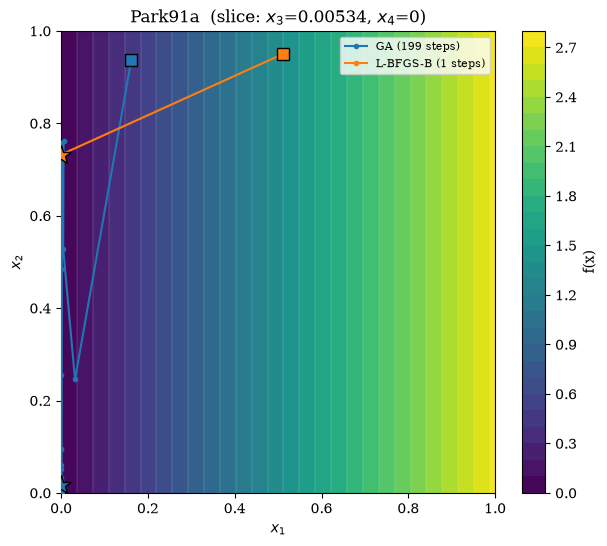

In [8]:
# Pymoo
problem = Park91a()

# Scipy
f, bounds = to_scipy(problem=problem)
method = "L-BFGS-B"


# Corremos 30 veces cada algoritmo y obtenemos un promedio
GA_mean_time = 0
GA_mean_invok = 0
GA_fx = []
# ==================== MEAN ====================
for i in range(1,31):
    # Algoritmo Genetico
    algorithm = GA(pop_size=100)
    res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=i)

    GA_mean_time += res_pymoo.exec_time
    GA_mean_invok += res_pymoo.algorithm.evaluator.n_eval
    GA_fx.append(float(res_pymoo.F[0]))

GA_mean_time = GA_mean_time / 30
GA_mean_invok = GA_mean_invok / 30

print("[GA] Tiempo promedio", GA_mean_time)
print("[GA] No. Invocaciones promedio", GA_mean_invok)


Scipy_mean_time = 0
Scipy_mean_invok = 0
Scipy_fx = []
for i in range(1, 31):
    # Scipy
    rng = np.random.default_rng(i)
    x0 = rng.uniform(problem.xl, problem.xu)

    inicio = time.perf_counter()
    res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds)  # traditional
    fin = time.perf_counter()

    Scipy_mean_time += (fin - inicio)
    Scipy_mean_invok += res_scipy.nfev
    Scipy_fx.append(float(res_scipy.fun))

Scipy_mean_invok = Scipy_mean_invok / 30
Scipy_mean_time =  Scipy_mean_time / 30

print(f"[{method}] Tiempo promedio", Scipy_mean_time)
print(f"[{method}] No. Invocaciones promedio", Scipy_mean_invok)

RESULSTS_mean[problem.foo_name] = {
    "GA": {
        "Time": GA_mean_time,
        "No_Invok": GA_mean_invok,
        "fx_mean": float(np.mean(GA_fx)),
        "fx_std":  float(np.std(GA_fx, ddof=1)),
        "fx_best": float(np.min(GA_fx)),
        "success_rate": float(np.mean(np.abs(np.array(GA_fx) - problem.f_opt) <= 1e-4)),

    },
    f"{method}": {
        "Time": Scipy_mean_time,
        "No_Invok": Scipy_mean_invok,
        "fx_mean": float(np.mean(Scipy_fx)),
        "fx_std":  float(np.std(Scipy_fx, ddof=1)),
        "fx_best": float(np.min(Scipy_fx)),
        "success_rate": float(np.mean(np.abs(np.array(Scipy_fx) - problem.f_opt) <= 1e-4)),
    }
}


# ==================== GRAPHS ====================
# Algoritmo Genetico
algorithm = GA(pop_size=100)
res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=15, save_history=True)

# Guardamos el historial de los pasos por epoca
path_pymoo_ga = pymoo_path(res_pymoo)

# Scipy
rng = np.random.default_rng(1)
x0 = rng.uniform(problem.xl, problem.xu)

# Guardamos el historial de los pasos por iteración
rec = ScipyRecorder(x0)    
inicio = time.perf_counter()
res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds, callback=rec)  # traditional
fin = time.perf_counter()
path_steps_scipy = rec.path


plot_steps(problem, {"GA": path_pymoo_ga, method : path_steps_scipy})
# surface = FitnessLandscape(problem, angle=(45, 45), _type="surface").show()          # 3-D surface




# ==================== RESULTS ====================
GA_result = {
    "Best_x": res_pymoo.X.tolist(), 
    "fx": res_pymoo.F[0], 
    "No_invok": res_pymoo.algorithm.evaluator.n_eval,
    "Time": res_pymoo.exec_time
}

Scipy_method = {
    "Best_x": res_scipy.x.tolist(), 
    "fx": res_scipy.fun, 
    "No_invok": res_scipy.nfev,
    "Time": fin - inicio
}

RESULSTS[problem.foo_name] = {
    "GA": GA_result,
    method: Scipy_method
}

print(json.dumps(RESULSTS_mean, indent=4))
print(json.dumps(RESULSTS, indent=4))



# Roos & Arnold (1963) Function

[GA] Tiempo promedio 0.400887934366862
[GA] No. Invocaciones promedio 20000.0
[L-BFGS-B] Tiempo promedio 0.003149473595355327
[L-BFGS-B] No. Invocaciones promedio 243.6
{
    "Rastrigin": {
        "GA": {
            "Time": 0.41114555994669594,
            "No_Invok": 20000.0,
            "fx_mean": 4.364392233687416e-06,
            "fx_std": 8.78557471960017e-06,
            "fx_best": 8.400036222155904e-11,
            "success_rate": 1.0
        },
        "L-BFGS-B": {
            "Time": 0.0008864083346755554,
            "No_Invok": 38.0,
            "fx_mean": 12.901221280309434,
            "fx_std": 10.158250077530292,
            "fx_best": 0.9949590570933005,
            "success_rate": 0.0
        }
    },
    "Branin": {
        "GA": {
            "Time": 0.4030147155125936,
            "No_Invok": 20000.0,
            "fx_mean": 0.3978877730653415,
            "fx_std": 1.1637895602594163e-06,
            "fx_best": 0.39788735797025865,
            "success_rate": 1.0

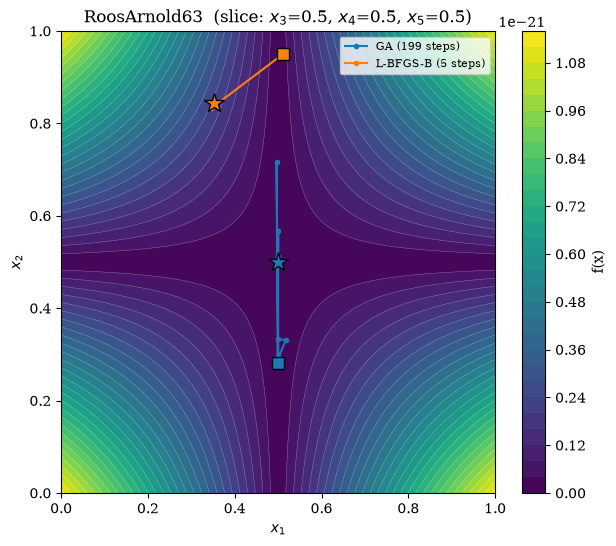

In [9]:
# Pymoo
problem = RoosArnold63()

# Scipy
f, bounds = to_scipy(problem=problem)
method = "L-BFGS-B"


# Corremos 30 veces cada algoritmo y obtenemos un promedio
GA_mean_time = 0
GA_mean_invok = 0
GA_fx = []
# ==================== MEAN ====================
for i in range(1,31):
    # Algoritmo Genetico
    algorithm = GA(pop_size=100)
    res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=i)

    GA_mean_time += res_pymoo.exec_time
    GA_mean_invok += res_pymoo.algorithm.evaluator.n_eval
    GA_fx.append(float(res_pymoo.F[0]))

GA_mean_time = GA_mean_time / 30
GA_mean_invok = GA_mean_invok / 30

print("[GA] Tiempo promedio", GA_mean_time)
print("[GA] No. Invocaciones promedio", GA_mean_invok)


Scipy_mean_time = 0
Scipy_mean_invok = 0
Scipy_fx = []
for i in range(1, 31):
    # Scipy
    rng = np.random.default_rng(i)
    x0 = rng.uniform(problem.xl, problem.xu)

    inicio = time.perf_counter()
    res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds)  # traditional
    fin = time.perf_counter()

    Scipy_mean_time += (fin - inicio)
    Scipy_mean_invok += res_scipy.nfev
    Scipy_fx.append(float(res_scipy.fun))

Scipy_mean_invok = Scipy_mean_invok / 30
Scipy_mean_time =  Scipy_mean_time / 30

print(f"[{method}] Tiempo promedio", Scipy_mean_time)
print(f"[{method}] No. Invocaciones promedio", Scipy_mean_invok)

RESULSTS_mean[problem.foo_name] = {
    "GA": {
        "Time": GA_mean_time,
        "No_Invok": GA_mean_invok,
        "fx_mean": float(np.mean(GA_fx)),
        "fx_std":  float(np.std(GA_fx, ddof=1)),
        "fx_best": float(np.min(GA_fx)),
        "success_rate": float(np.mean(np.abs(np.array(GA_fx) - problem.f_opt) <= 1e-4)),

    },
    f"{method}": {
        "Time": Scipy_mean_time,
        "No_Invok": Scipy_mean_invok,
        "fx_mean": float(np.mean(Scipy_fx)),
        "fx_std":  float(np.std(Scipy_fx, ddof=1)),
        "fx_best": float(np.min(Scipy_fx)),
        "success_rate": float(np.mean(np.abs(np.array(Scipy_fx) - problem.f_opt) <= 1e-4)),
    }
}


# ==================== GRAPHS ====================
# Algoritmo Genetico
algorithm = GA(pop_size=100)
res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=15, save_history=True)

# Guardamos el historial de los pasos por epoca
path_pymoo_ga = pymoo_path(res_pymoo)

# Scipy
rng = np.random.default_rng(1)
x0 = rng.uniform(problem.xl, problem.xu)

# Guardamos el historial de los pasos por iteración
rec = ScipyRecorder(x0)    
inicio = time.perf_counter()
res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds, callback=rec)  # traditional
fin = time.perf_counter()
path_steps_scipy = rec.path


plot_steps(problem, {"GA": path_pymoo_ga, method : path_steps_scipy})
# surface = FitnessLandscape(problem, angle=(45, 45), _type="surface").show()          # 3-D surface




# ==================== RESULTS ====================
GA_result = {
    "Best_x": res_pymoo.X.tolist(), 
    "fx": res_pymoo.F[0], 
    "No_invok": res_pymoo.algorithm.evaluator.n_eval,
    "Time": res_pymoo.exec_time
}

Scipy_method = {
    "Best_x": res_scipy.x.tolist(), 
    "fx": res_scipy.fun, 
    "No_invok": res_scipy.nfev,
    "Time": fin - inicio
}

RESULSTS[problem.foo_name] = {
    "GA": GA_result,
    method: Scipy_method
}

print(json.dumps(RESULSTS_mean, indent=4))
print(json.dumps(RESULSTS, indent=4))



# Discontinuous Integrand Family

[GA] Tiempo promedio 0.46467487812042235
[GA] No. Invocaciones promedio 20000.0
[L-BFGS-B] Tiempo promedio 0.0001444250054191798
[L-BFGS-B] No. Invocaciones promedio 3.9
{
    "Rastrigin": {
        "GA": {
            "Time": 0.41114555994669594,
            "No_Invok": 20000.0,
            "fx_mean": 4.364392233687416e-06,
            "fx_std": 8.78557471960017e-06,
            "fx_best": 8.400036222155904e-11,
            "success_rate": 1.0
        },
        "L-BFGS-B": {
            "Time": 0.0008864083346755554,
            "No_Invok": 38.0,
            "fx_mean": 12.901221280309434,
            "fx_std": 10.158250077530292,
            "fx_best": 0.9949590570933005,
            "success_rate": 0.0
        }
    },
    "Branin": {
        "GA": {
            "Time": 0.4030147155125936,
            "No_Invok": 20000.0,
            "fx_mean": 0.3978877730653415,
            "fx_std": 1.1637895602594163e-06,
            "fx_best": 0.39788735797025865,
            "success_rate": 1.

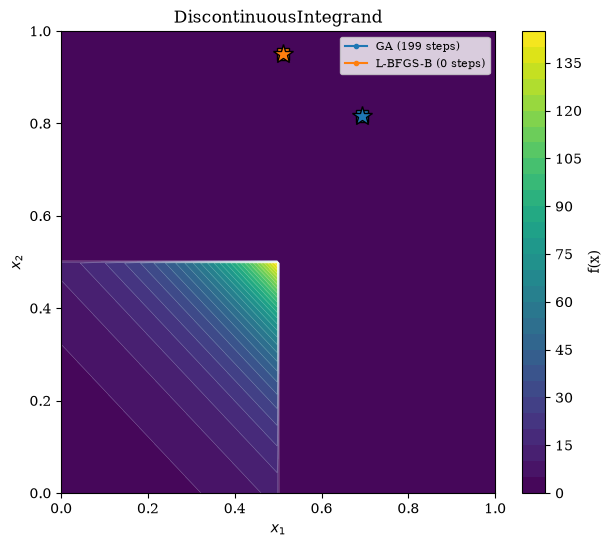

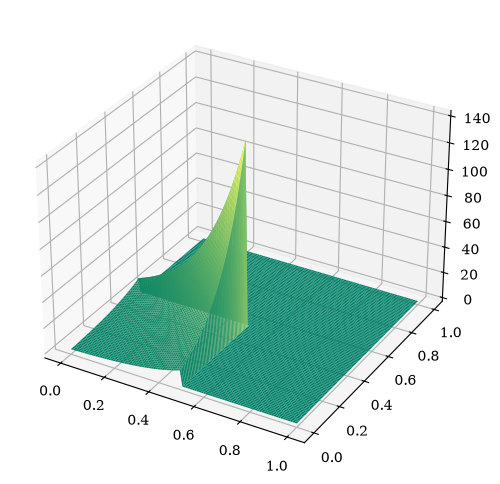

In [10]:
# Pymoo
problem = DiscontinuousIntegrand()

# Scipy
f, bounds = to_scipy(problem=problem)
method = "L-BFGS-B"


# Corremos 30 veces cada algoritmo y obtenemos un promedio
GA_mean_time = 0
GA_mean_invok = 0
GA_fx = []
# ==================== MEAN ====================
for i in range(1,31):
    # Algoritmo Genetico
    algorithm = GA(pop_size=100)
    res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=i)

    GA_mean_time += res_pymoo.exec_time
    GA_mean_invok += res_pymoo.algorithm.evaluator.n_eval
    GA_fx.append(float(res_pymoo.F[0]))

GA_mean_time = GA_mean_time / 30
GA_mean_invok = GA_mean_invok / 30

print("[GA] Tiempo promedio", GA_mean_time)
print("[GA] No. Invocaciones promedio", GA_mean_invok)


Scipy_mean_time = 0
Scipy_mean_invok = 0
Scipy_fx = []
for i in range(1, 31):
    # Scipy
    rng = np.random.default_rng(i)
    x0 = rng.uniform(problem.xl, problem.xu)

    inicio = time.perf_counter()
    res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds)  # traditional
    fin = time.perf_counter()

    Scipy_mean_time += (fin - inicio)
    Scipy_mean_invok += res_scipy.nfev
    Scipy_fx.append(float(res_scipy.fun))

Scipy_mean_invok = Scipy_mean_invok / 30
Scipy_mean_time =  Scipy_mean_time / 30

print(f"[{method}] Tiempo promedio", Scipy_mean_time)
print(f"[{method}] No. Invocaciones promedio", Scipy_mean_invok)

RESULSTS_mean[problem.foo_name] = {
    "GA": {
        "Time": GA_mean_time,
        "No_Invok": GA_mean_invok,
        "fx_mean": float(np.mean(GA_fx)),
        "fx_std":  float(np.std(GA_fx, ddof=1)),
        "fx_best": float(np.min(GA_fx)),
        "success_rate": float(np.mean(np.abs(np.array(GA_fx) - problem.f_opt) <= 1e-4)),

    },
    f"{method}": {
        "Time": Scipy_mean_time,
        "No_Invok": Scipy_mean_invok,
        "fx_mean": float(np.mean(Scipy_fx)),
        "fx_std":  float(np.std(Scipy_fx, ddof=1)),
        "fx_best": float(np.min(Scipy_fx)),
        "success_rate": float(np.mean(np.abs(np.array(Scipy_fx) - problem.f_opt) <= 1e-4)),
    }
}


# ==================== GRAPHS ====================
# Algoritmo Genetico
algorithm = GA(pop_size=100)
res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=15, save_history=True)

# Guardamos el historial de los pasos por epoca
path_pymoo_ga = pymoo_path(res_pymoo)

# Scipy
rng = np.random.default_rng(1)
x0 = rng.uniform(problem.xl, problem.xu)

# Guardamos el historial de los pasos por iteración
rec = ScipyRecorder(x0)    
inicio = time.perf_counter()
res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds, callback=rec)  # traditional
fin = time.perf_counter()
path_steps_scipy = rec.path


plot_steps(problem, {"GA": path_pymoo_ga, method : path_steps_scipy})
surface = FitnessLandscape(problem, angle=(45, 45), _type="surface").show()          # 3-D surface




# ==================== RESULTS ====================
GA_result = {
    "Best_x": res_pymoo.X.tolist(), 
    "fx": res_pymoo.F[0], 
    "No_invok": res_pymoo.algorithm.evaluator.n_eval,
    "Time": res_pymoo.exec_time
}

Scipy_method = {
    "Best_x": res_scipy.x.tolist(), 
    "fx": res_scipy.fun, 
    "No_invok": res_scipy.nfev,
    "Time": fin - inicio
}

RESULSTS[problem.foo_name] = {
    "GA": GA_result,
    method: Scipy_method
}

print(json.dumps(RESULSTS_mean, indent=4))
print(json.dumps(RESULSTS, indent=4))



# Environmental Model Function

[GA] Tiempo promedio 0.5344001770019531
[GA] No. Invocaciones promedio 20000.0
[L-BFGS-B] Tiempo promedio 0.0053308348016192515
[L-BFGS-B] No. Invocaciones promedio 140.0
{
    "Rastrigin": {
        "GA": {
            "Time": 0.41114555994669594,
            "No_Invok": 20000.0,
            "fx_mean": 4.364392233687416e-06,
            "fx_std": 8.78557471960017e-06,
            "fx_best": 8.400036222155904e-11,
            "success_rate": 1.0
        },
        "L-BFGS-B": {
            "Time": 0.0008864083346755554,
            "No_Invok": 38.0,
            "fx_mean": 12.901221280309434,
            "fx_std": 10.158250077530292,
            "fx_best": 0.9949590570933005,
            "success_rate": 0.0
        }
    },
    "Branin": {
        "GA": {
            "Time": 0.4030147155125936,
            "No_Invok": 20000.0,
            "fx_mean": 0.3978877730653415,
            "fx_std": 1.1637895602594163e-06,
            "fx_best": 0.39788735797025865,
            "success_rate": 1

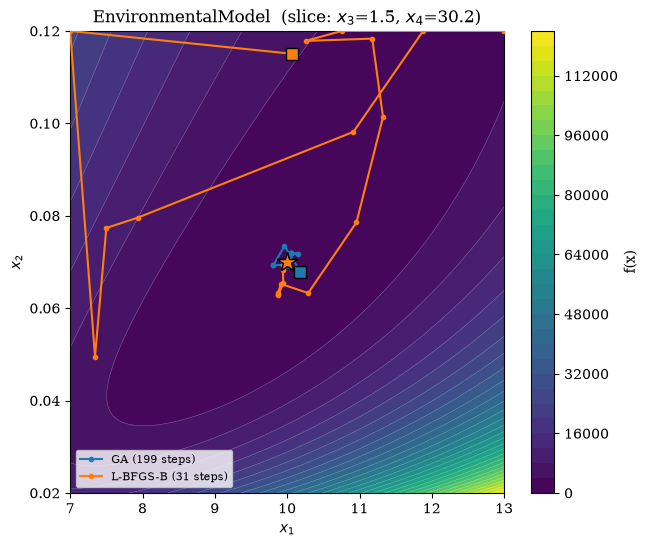

In [11]:
# Pymoo
problem = EnvironmentalModel()

# Scipy
f, bounds = to_scipy(problem=problem)
method = "L-BFGS-B"


# Corremos 30 veces cada algoritmo y obtenemos un promedio
GA_mean_time = 0
GA_mean_invok = 0
GA_fx = []
# ==================== MEAN ====================
for i in range(1,31):
    # Algoritmo Genetico
    algorithm = GA(pop_size=100)
    res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=i)

    GA_mean_time += res_pymoo.exec_time
    GA_mean_invok += res_pymoo.algorithm.evaluator.n_eval
    GA_fx.append(float(res_pymoo.F[0]))

GA_mean_time = GA_mean_time / 30
GA_mean_invok = GA_mean_invok / 30

print("[GA] Tiempo promedio", GA_mean_time)
print("[GA] No. Invocaciones promedio", GA_mean_invok)


Scipy_mean_time = 0
Scipy_mean_invok = 0
Scipy_fx = []
for i in range(1, 31):
    # Scipy
    rng = np.random.default_rng(i)
    x0 = rng.uniform(problem.xl, problem.xu)

    inicio = time.perf_counter()
    res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds)  # traditional
    fin = time.perf_counter()

    Scipy_mean_time += (fin - inicio)
    Scipy_mean_invok += res_scipy.nfev
    Scipy_fx.append(float(res_scipy.fun))

Scipy_mean_invok = Scipy_mean_invok / 30
Scipy_mean_time =  Scipy_mean_time / 30

print(f"[{method}] Tiempo promedio", Scipy_mean_time)
print(f"[{method}] No. Invocaciones promedio", Scipy_mean_invok)

RESULSTS_mean[problem.foo_name] = {
    "GA": {
        "Time": GA_mean_time,
        "No_Invok": GA_mean_invok,
        "fx_mean": float(np.mean(GA_fx)),
        "fx_std":  float(np.std(GA_fx, ddof=1)),
        "fx_best": float(np.min(GA_fx)),
        "success_rate": float(np.mean(np.abs(np.array(GA_fx) - problem.f_opt) <= 1e-4)),

    },
    f"{method}": {
        "Time": Scipy_mean_time,
        "No_Invok": Scipy_mean_invok,
        "fx_mean": float(np.mean(Scipy_fx)),
        "fx_std":  float(np.std(Scipy_fx, ddof=1)),
        "fx_best": float(np.min(Scipy_fx)),
        "success_rate": float(np.mean(np.abs(np.array(Scipy_fx) - problem.f_opt) <= 1e-4)),
    }
}


# ==================== GRAPHS ====================
# Algoritmo Genetico
algorithm = GA(pop_size=100)
res_pymoo = minimize(problem, algorithm, termination=("n_gen", 200), seed=15, save_history=True)

# Guardamos el historial de los pasos por epoca
path_pymoo_ga = pymoo_path(res_pymoo)

# Scipy
rng = np.random.default_rng(1)
x0 = rng.uniform(problem.xl, problem.xu)

# Guardamos el historial de los pasos por iteración
rec = ScipyRecorder(x0)    
inicio = time.perf_counter()
res_scipy  = scipy_minimize(f, x0=x0, method=method, bounds=bounds, callback=rec)  # traditional
fin = time.perf_counter()
path_steps_scipy = rec.path


plot_steps(problem, {"GA": path_pymoo_ga, method : path_steps_scipy})
# surface = FitnessLandscape(problem, angle=(45, 45), _type="surface").show()          # 3-D surface




# ==================== RESULTS ====================
GA_result = {
    "Best_x": res_pymoo.X.tolist(), 
    "fx": res_pymoo.F[0], 
    "No_invok": res_pymoo.algorithm.evaluator.n_eval,
    "Time": res_pymoo.exec_time
}

Scipy_method = {
    "Best_x": res_scipy.x.tolist(), 
    "fx": res_scipy.fun, 
    "No_invok": res_scipy.nfev,
    "Time": fin - inicio
}

RESULSTS[problem.foo_name] = {
    "GA": GA_result,
    method: Scipy_method
}

print(json.dumps(RESULSTS_mean, indent=4))
print(json.dumps(RESULSTS, indent=4))



## Guardamos los resultados

In [12]:
with open("results/T3/Promedios_resultados.json", "w") as f:
    json.dump(RESULSTS_mean, f, indent=4)


with open("results/T3/Comparacion_resultados.json", "w") as f:
    json.dump(RESULSTS, f, indent=4)